# 03 · Riesgo de mercado: VaR, CVaR y backtesting

**Bloque 3.** Objetivo: medir el riesgo de cola de los portafolios del notebook 02 con VaR y CVaR, y comprobar
con datos fuera de muestra si esos pronósticos de riesgo se cumplen (prueba de Kupiec).

Un VaR al 99% dice: "solo 1 de cada 100 días debería perderse más que esto". Esa afirmación se puede verificar
contando cuántas veces se rompió. A cada día en que la pérdida supera al VaR se le llama **excepción**.

In [1]:
import sys
from pathlib import Path

# Permite importar `src` al ejecutar desde la carpeta notebooks/
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import backtest, config, data, metrics, plots, portfolios, risk

plots.set_style()
TD = config.TRADING_DAYS

## 1. Portafolios a evaluar

Se reconstruyen los retornos netos de costos del notebook 02 (mismas reglas: ventana de 252 días, rebalanceo mensual, 10 pb).
El análisis detallado usa el portafolio **igual ponderado**, que es el más transparente; al final se repite para todos.

In [2]:
prices = data.clean_prices(data.download_prices())
stock_rets, bench_rets = data.split_benchmark(data.compute_returns(prices, log=False))

STRATEGIES = {
    "Igual ponderado": portfolios.equal_weight,
    "Mínima varianza": portfolios.min_variance,
    "HRP": portfolios.hrp,
    "Máximo Sharpe": portfolios.max_sharpe,
}
port_rets = pd.DataFrame({name: backtest.walk_forward_backtest(stock_rets, fn)[0] for name, fn in STRATEGIES.items()})
port_rets["NAFTRAC"] = bench_rets.loc[port_rets.index]

MAIN = "Igual ponderado"
r = port_rets[MAIN]
print(f"Portafolio principal: {MAIN} | {len(r)} retornos diarios | {r.index.min().date()} → {r.index.max().date()}")

Portafolio principal: Igual ponderado | 2572 retornos diarios | 2016-07-19 → 2026-10-08


## 2. VaR y CVaR con toda la muestra

- **VaR histórico:** el cuantil de las pérdidas observadas. No supone ninguna distribución.
- **VaR paramétrico (normal):** supone retornos normales con la media y la desviación de la muestra.
- **CVaR (Expected Shortfall):** la pérdida *promedio* en los días que superan al VaR. Responde a "cuando sale mal, ¿qué tan mal?".

Todo se reporta como pérdida diaria positiva.

In [3]:
rows = {}
for alpha in (0.95, 0.99):
    rows[f"{alpha:.0%}"] = {
        "VaR histórico": risk.var_historical(r, alpha),
        "VaR normal": risk.var_parametric(r, alpha),
        "CVaR histórico": risk.cvar_historical(r, alpha),
        "CVaR normal": risk.cvar_parametric(r, alpha),
    }
static = pd.DataFrame(rows).T
static["VaR histórico / normal"] = static["VaR histórico"] / static["VaR normal"]
static["CVaR histórico / normal"] = static["CVaR histórico"] / static["CVaR normal"]
display(static.style.format({c: "{:.2%}" for c in static.columns[:4]} | {c: "{:.2f}" for c in static.columns[4:]}))

print(f"Curtosis en exceso del portafolio: {r.kurt():.1f} | asimetría: {r.skew():.2f}")

,VaR histórico,VaR normal,CVaR histórico,CVaR normal,VaR histórico / normal,CVaR histórico / normal
95%,1.40%,1.58%,2.21%,1.99%,0.89,1.11
99%,2.42%,2.25%,3.99%,2.59%,1.08,1.54


Curtosis en exceso del portafolio: 5.1 | asimetría: -0.52


**Comentarios:**
- **VaR histórico vs VaR normal:** El VaR normal sobreestima el riesgo en el nivel de confianza de 95% por 0.18 puntos porcentuales, mientras que lo subestima por 0.17 puntos con nivel de confianza de 99%. Esto implica que los casos extremos están más cargados en las puntas.
- **CVaR histórico vs CVaR normal:** En este caso, el CVaR normal subestima el promedio de pérdida en los casos excepcionales en ambos niveles de confianza. Para el nivel de confianza de 99% hay una diferencia muy importante de 1.40 puntos entre la pérdida promedio esperada y la real. Esto demuestra que los casos extremos de pérdida son mucho más altos de lo que una distribución normal esperaría.
- **Relación con colas pesadas:** Estos resultados coinciden con la alta proporción de colas pesadas por emisora que se vio en el notebook 01 y siguen el mismo patrón, lo que confirma la teoría previa.

## 3. VaR rodante: el pronóstico que se habría tenido cada día

El cálculo anterior usa toda la muestra, así que no sirve para evaluar un modelo: ya conoce el futuro.
Aquí el VaR de cada día se calcula **solo con datos hasta el día anterior**, con cuatro métodos:

| Método | Cómo estima el riesgo | Qué problema ataca |
|---|---|---|
| Histórico | Cuantil empírico de los últimos 252 días | Colas pesadas |
| Normal | Media y desviación de los últimos 252 días, con distribución normal | Ninguno (línea base) |
| EWMA | Normal con volatilidad EWMA (λ = 0.94, el valor estándar de RiskMetrics), que pesa más los días recientes | Agrupamiento de volatilidad |
| Histórico filtrado | Cuantil empírico de los retornos divididos entre su volatilidad EWMA, escalado por la volatilidad actual | Ambos |

Los parámetros (252 días, λ = 0.94) son los convencionales y se fijaron de antemano; no se ajustaron para mejorar el resultado.
El histórico filtrado se agregó después de ver los resultados de los otros tres (ver advertencias).

Periodo de prueba: 2017-07-20 → 2026-10-08 (2319 días)


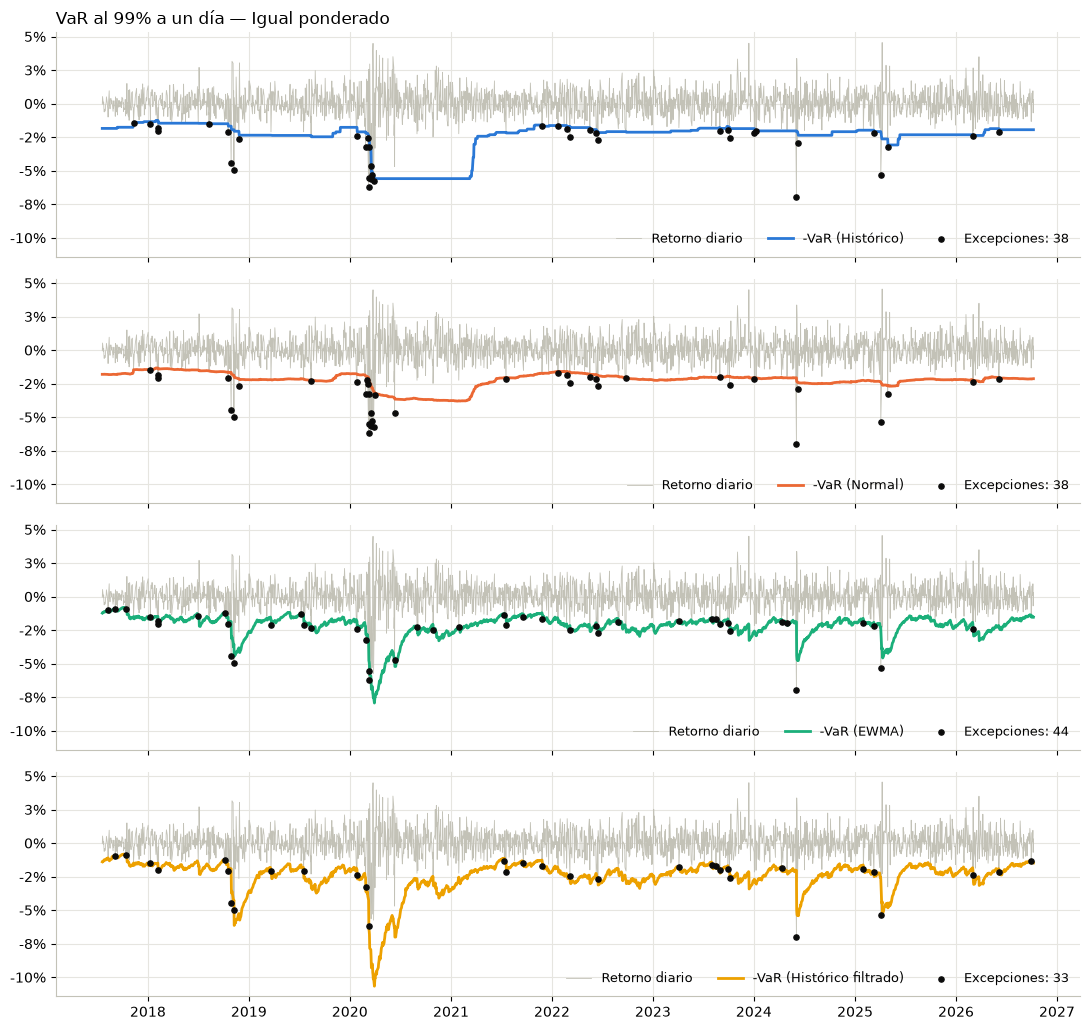

In [9]:
WINDOW = 252
METHODS = {"Histórico": "historical", "Normal": "parametric", "EWMA": "ewma", "Histórico filtrado": "fhs"}

def forecasts(returns: pd.Series, alpha: float) -> pd.DataFrame:
    return pd.DataFrame({name: risk.rolling_var(returns, window=WINDOW, alpha=alpha, method=m) for name, m in METHODS.items()}).dropna()

var99 = forecasts(r, 0.99)
print(f"Periodo de prueba: {var99.index.min().date()} → {var99.index.max().date()} ({len(var99)} días)")

plots.var_chart(r, var99, f"VaR al 99% a un día — {MAIN}")
plt.show()

**Comentarios:**
- **VaR histórico:** Tiene una respuesta lenta cuando sube la volatilidad y además tiene el periodo más largo de bajada después de un periodo de alta volatilidad. Se concentran las excepciones en las crisis.
- **VaR normal:** Tiene la menor reacción de todos; es el que menos se mueve. Pero se mantiene relativamente cerca de la volatilidad la mayoría del tiempo. Mala reacción en época de crisis. Se concentran las excepciones en las crisis.
- **VaR EWMA:** Es el que se queda más pegado a la fluctuación de volatilidad. Reacciona rápido a las subidas y vuelve a bajar con agilidad. Es el que tiene mayor número de excepciones porque usa el número de la normal, que se queda corto para este caso.
- **VaR histórico filtrado:** Reacciona tan rápido como EWMA a un aumento de volatilidad y tiene los picos más altos. Se tarda más que EWMA en volver, pero no tanto como el histórico. Es el que tiene la menor cantidad de excepciones. El mayor grupo de excepciones está en la segunda mitad de 2023.

## 4. Backtesting: ¿se cumple lo que promete el VaR?

La **prueba de Kupiec** compara el número de excepciones observado con el esperado.
La hipótesis nula es que la tasa de excepciones es la correcta (1% o 5%); un *p-value* menor a 0.05 la rechaza,
es decir, el modelo está mal calibrado. Rechazar puede deberse a demasiadas excepciones (subestima el riesgo)
o a muy pocas (lo sobreestima y obliga a guardar capital de más).

In [5]:
def kupiec_table(returns: pd.Series) -> pd.DataFrame:
    rows = {}
    for alpha in (0.95, 0.99):
        fc = forecasts(returns, alpha)
        for name in METHODS:
            rows[(f"{alpha:.0%}", name)] = risk.backtest_var(returns, fc[name], alpha)
    return pd.DataFrame(rows).T.rename_axis(["Nivel", "Método"])

FMT = {"Días": "{:.0f}", "Excepciones": "{:.0f}", "Esperadas": "{:.1f}", "Tasa": "{:.2%}", "Kupiec LR": "{:.2f}",
       "p-value": "{:.3f}", "VaR medio": "{:.2%}", "Pérdida media en excepción": "{:.2%}"}
kupiec = kupiec_table(r)
kupiec.style.format(FMT)

**Comentarios:**
- **Métodos que pasan la prueba:** Todas las pruebas al 95% están dentro de rango y pasan la prueba. Su tasa de excepciones se desvía a lo más medio punto porcentual del 5% esperado, siendo EWMA la más cercana al número esperado de excepciones. De las pruebas al 99%, solo el histórico filtrado pasa la prueba y con un margen muy pequeño.
- **Métodos rechazados por la prueba:** El histórico, el normal y el EWMA al 99% no pasan la prueba, siendo el EWMA el más alejado de todos. Además, los tres modelos subestiman el riesgo, pues hay muchas más excepciones reales que esperadas. Esto es peligroso y puede implicar pérdidas reales.
- **Pérdida cuando falla el VaR:** Cuando el VaR se rompe, la pérdida es bastante mayor que el umbral. Al 99%, en los métodos de ventana fija la pérdida media en excepción (3.09% en el histórico y 3.25% en el normal) supera claramente a su VaR medio (2.42% y 2.21%). El VaR dice dónde empieza la cola, no cuánto se pierde dentro de ella.

## 5. ¿Cuándo ocurren las excepciones?

Kupiec solo cuenta excepciones. Un buen modelo además debería tenerlas repartidas en el tiempo:
si llegan en racimo, el modelo falla justo cuando más se necesita.

In [6]:
hits99 = var99.apply(lambda var: (-r.loc[var.index] > var))
by_year = hits99.groupby(hits99.index.year).sum()
by_year.loc["Total"] = by_year.sum()
display(by_year.style.format("{:.0f}").set_caption("Excepciones al 99% por año"))

crash = hits99.loc["2020-02-20":"2020-04-30"]
print(f"Entre el 20-feb y el 30-abr de 2020 ({len(crash)} días) se esperaban {len(crash) * 0.01:.1f} excepciones. Observadas:")
print(crash.sum().to_string())

,Histórico,Normal,EWMA,Histórico filtrado
Date,,,,
2017,1,0,3,2
2018,8,7,8,6
2019,0,1,4,2
2020,10,13,7,3
2021,1,1,5,4
2022,6,7,4,2
2023,3,2,6,6
2024,4,3,3,2
2025,3,2,3,3


Entre el 20-feb y el 30-abr de 2020 (48 días) se esperaban 0.5 excepciones. Observadas:
Histórico              9
Normal                11
EWMA                   3
Histórico filtrado     2


**Comentarios:**
- **Agrupación de excepciones:** Es más probable que una excepción venga después de otra excepción. Esto se ve reflejado en los modelos EWMA e histórico filtrado, que consideran este factor con mucho mayor peso y solo tuvieron 3 y 2 excepciones respectivamente durante la crisis de la pandemia de COVID-19, a diferencia de los otros 2 métodos, que promediaron 10 excepciones en ese mismo periodo. Aun así, se esperaba menos de una (0.5).
- **Recuperación:** El EWMA tuvo una muy buena recuperación en marzo de 2020 después del momento de mayor volatilidad en la crisis, seguido del histórico filtrado. Ambos modelos muestran buena capacidad de volver.
- **Hipótesis previas:** En la primera parte notamos que la volatilidad de un día tiene impacto en los días próximos; esto se aplica para algunos de los modelos actuales, como EWMA y el histórico filtrado.

## 6. Los mismos resultados para todos los portafolios

Excepciones observadas y *p-value* de Kupiec al 99% para cada portafolio y método, sobre el mismo periodo de prueba.

In [11]:
summary = {}
for name in port_rets.columns:
    fc = forecasts(port_rets[name], 0.99)
    for method in METHODS:
        out = risk.backtest_var(port_rets[name], fc[method], 0.99)
        summary[(name, method)] = {"Excepciones": out["Excepciones"], "p-value": out["p-value"]}
summary = pd.DataFrame(summary).T.unstack()
summary.columns = [f"{method} · {stat}" for stat, method in summary.columns]
summary = summary[[f"{m} · {s}" for m in METHODS for s in ("Excepciones", "p-value")]].loc[port_rets.columns]
expected = len(forecasts(r, 0.99)) * 0.01
print(f"Excepciones esperadas al 99%: {expected:.1f}")
summary.style.format({c: "{:.0f}" if "Excepciones" in c else "{:.3f}" for c in summary.columns})

Excepciones esperadas al 99%: 23.2


,Histórico · Excepciones,Histórico · p-value,Normal · Excepciones,Normal · p-value,EWMA · Excepciones,EWMA · p-value,Histórico filtrado · Excepciones,Histórico filtrado · p-value
Igual ponderado,38,0.005,38,0.005,44,0.000,33,0.054
Mínima varianza,39,0.003,36,0.013,31,0.121,31,0.121
HRP,34,0.035,36,0.013,37,0.008,27,0.438
Máximo Sharpe,37,0.008,42,0.000,40,0.001,30,0.174
NAFTRAC,36,0.013,38,0.005,41,0.001,30,0.174


**Comentarios:**
- **Revisión con los otros portafolios:** Se mantiene una tendencia bastante similar en los resultados. El rango de excepciones se mantiene. La principal excepción es que EWMA no se rechaza en el portafolio de mínima varianza, pero no hay una razón clara para ello y no lo tomaría como evidencia a favor de EWMA.
- **Histórico filtrado:** El histórico filtrado sigue siendo el más cercano a las excepciones esperadas (empatado con EWMA en mínima varianza) y es el único que pasa la prueba en todos los portafolios. Es el único método que pasó la prueba de Kupiec, aunque subestimó el riesgo y tuvo más excepciones de las esperadas.

## 7. Advertencias metodológicas

- **Selección de modelo.** El histórico filtrado se añadió después de ver que los tres primeros métodos fallaban al 99%.
  Es un método estándar y se justifica con los hechos estilizados del notebook 01, pero haberlo elegido después de ver
  los datos significa que su buen resultado debe confirmarse en otro periodo u otro mercado.
- **Kupiec no revisa independencia.** Un modelo puede acertar el número de excepciones y aun así tenerlas agrupadas
  (sección 5). La prueba de Christoffersen cubre ese caso y queda como trabajo futuro.
- **Poca potencia al 99%.** Con unas 23 excepciones esperadas, la prueba distingue mal entre un modelo correcto y uno ligeramente
  descalibrado; no rechazar no demuestra que el modelo sea bueno.
- **VaR a un día.** No se escala a horizontes más largos; la regla de la raíz del tiempo supone retornos independientes,
  que el agrupamiento de volatilidad contradice.
- **Los retornos del portafolio heredan las limitaciones del backtest**: sesgo de supervivencia en el universo y costos simplificados.
- **El VaR no dice cuánto se pierde más allá del umbral.** Por eso se reporta junto con el CVaR.

## 8. Conclusiones del Bloque 3

- ¿Qué método de VaR usarías para este portafolio y por qué?  
Utilizaría el método de histórico filtrado, pues reacciona bien ante el aumento de volatilidad, vuelve con velocidad a periodos más estables y, sobre todo, mantiene una cantidad de excepciones acorde a la cantidad esperada para un rango de 95%, y es el único método que pasa la prueba de Kupiec al 99%, aunque por poco. Hay que considerar que este método se agregó después de ver fallar a los otros tres, por lo que su resultado debería confirmarse en otro periodo o en otro mercado.
- ¿Qué tan grave es suponer normalidad? ¿En qué nivel de confianza importa más?  
Depende del nivel de confianza. Al 95% no es tan grave como podría esperarse: la diferencia es poco notoria e incluso sobreestima el riesgo. Al 99% sí lo es: presenta diferencias visibles en el cálculo del umbral y su mayor riesgo es la subestimación del CVaR en 1.4 puntos (2.59% contra 3.99% real). Además, EWMA e histórico filtrado usan la misma volatilidad y solo difieren en el supuesto normal, y EWMA tuvo 44 excepciones contra 33. Cabe recalcar que no es la opción ideal.
- ¿Qué aporta el CVaR que el VaR no da?  
La principal función del CVaR es saber cuánto bajará en promedio el portafolio cuando se cumpla la excepción que señala el VaR: en ese 1% o 5% de días en que se baje del umbral establecido, ¿cuánto dinero se perderá en promedio?
- ¿Qué enseñó marzo de 2020 sobre los modelos con ventana fija?  
Lo que mostró la crisis de COVID-19 a inicios de 2020 es que las ventanas fijas no tienen la capacidad de reaccionar a las crisis ni a situaciones en las que la volatilidad se dispara, dando muchas más excepciones de las que deberían.
- ¿Qué limitaciones tiene la prueba de Kupiec?  
La prueba de Kupiec sirve para revisar si la cantidad total de excepciones en un periodo corresponde a la cantidad que se puede esperar para ese nivel de confianza. La principal limitación es que mide el número absoluto de fallas y no cuándo pasaron ni en qué condiciones.